# Smart Watering: Decision Tree
ICS 3202 | CAT 2 | Ian, Devyan and Alfred

**Question:** Can a decision tree predict when an outdoor garden plant needs water?

| Order | Presenter | Part | Time |
|---|---|---|---|
| 1 | Ian | Data and cleaning | 4 minutes |
| 2 | Devyan | Labels and exploration | 4 minutes |
| 3 | Alfred | Training and results | 4 minutes |

Each person has six short sections. Run all cells from top to bottom.


## 1. Ian: Data and cleaning
### 1.1 Our approach
We use **supervised binary classification**: water today (1) or wait (0). The base model is a Decision Tree. The app is intended to work without soil sensors.


In [ ]:
from pathlib import Path
import json, hashlib, platform, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
VERSIONS = {p: importlib.metadata.version(p) for p in
            ["numpy", "pandas", "matplotlib", "seaborn", "scikit-learn", "requests", "joblib"]}


### 1.2 Load the weather data
We use daily ERA5 weather for Nairobi, 2015-2025, from Open-Meteo. The CSV and source details are saved so we can repeat the run.


In [ ]:
URL = "https://archive-api.open-meteo.com/v1/archive"
PARAMS = {"latitude": -1.2921, "longitude": 36.8219,
          "start_date": "2015-01-01", "end_date": "2025-12-31",
          "daily": "temperature_2m_max,temperature_2m_min,temperature_2m_mean,relative_humidity_2m_mean,precipitation_sum,et0_fao_evapotranspiration,wind_speed_10m_max",
          "timezone": "Africa/Nairobi", "models": "era5",
          "temperature_unit": "celsius", "wind_speed_unit": "kmh", "precipitation_unit": "mm"}
RAW_PATH = Path("nairobi_era5_daily_2015_2025.csv")
META_PATH = Path("weather_provenance.json")
if RAW_PATH.exists():
    if not META_PATH.exists():
        raise ValueError("Cached CSV has no provenance. Restore its metadata or rename the CSV and rerun.")
    provenance = json.loads(META_PATH.read_text())
    assert provenance["request"] == PARAMS, "Cached request does not match this notebook."
    assert hashlib.sha256(RAW_PATH.read_bytes()).hexdigest() == provenance["sha256"], "Cached CSV checksum mismatch."
    raw = pd.read_csv(RAW_PATH)
else:
    response = requests.get(URL, params=PARAMS, timeout=120)
    response.raise_for_status()
    payload = response.json()
    if payload.get("error"):
        raise ValueError(payload.get("reason", "Weather API error"))
    raw = pd.DataFrame(payload["daily"])
    raw.to_csv(RAW_PATH, index=False)
    provenance = {"source": URL, "request": PARAMS, "resolved_url": response.url,
                  "retrieved_utc": pd.Timestamp.now(tz="UTC").isoformat(),
                  "daily_units": payload["daily_units"],
                  "location": {k: payload.get(k) for k in ["latitude", "longitude", "elevation", "timezone"]},
                  "sha256": hashlib.sha256(RAW_PATH.read_bytes()).hexdigest()}
    META_PATH.write_text(json.dumps(provenance, indent=2))
print("Source:", provenance["source"], "| requested model:", PARAMS["models"])
print("Location:", provenance["location"])
print("Raw shape:", raw.shape, "| SHA256:", provenance["sha256"])
display(raw.head())


Source: https://archive-api.open-meteo.com/v1/archive | requested model: era5
Location: {'latitude': -1.25, 'longitude': 36.75, 'elevation': 1668.0, 'timezone': 'Africa/Nairobi'}
Raw shape: (4018, 8) | SHA256: b5d3ab20d074e95a4b76428d4f21974494224c0c9e6aaac9aeaf036a67dfcebb


,time,temperature_2m_max,temperature_2m_min,temperature_2m_mean,relative_humidity_2m_mean,precipitation_sum,et0_fao_evapotranspiration,wind_speed_10m_max
0,2015-01-01,28.0,12.6,20.3,52,0.0,5.84,18.3
1,2015-01-02,28.6,11.9,20.8,42,0.0,6.66,19.1
2,2015-01-03,29.5,12.7,20.9,40,0.0,6.22,18.3
3,2015-01-04,30.2,13.3,21.5,40,0.0,5.62,12.6
4,2015-01-05,29.8,13.8,21.8,49,0.0,4.71,11.9


### 1.3 Fix the format and check missing values
Convert the date and numeric columns, then sort by date. Missing rainfall is not treated as zero. Missing data must be resolved before modelling.


In [ ]:
print(raw.dtypes)
weather = raw.rename(columns={"time": "date", "temperature_2m_max": "temp_max",
    "temperature_2m_min": "temp_min", "temperature_2m_mean": "temp_mean",
    "relative_humidity_2m_mean": "humidity_mean", "precipitation_sum": "rain",
    "et0_fao_evapotranspiration": "et0", "wind_speed_10m_max": "wind_max"}).copy()
weather["date"] = pd.to_datetime(weather["date"], errors="raise")
num_cols = ["temp_max", "temp_min", "temp_mean", "humidity_mean", "rain", "et0", "wind_max"]
weather[num_cols] = weather[num_cols].apply(pd.to_numeric, errors="raise")
weather = weather.sort_values("date").reset_index(drop=True)
print("After renaming, conversion and sorting:", weather.shape)
display(weather.dtypes)

print(weather.isna().sum())
assert not weather.isna().any().any(), "Missing data: resolve from the source before simulation. Missing rain is not zero rain."
assert np.isfinite(weather[num_cols].to_numpy()).all(), "Non-finite weather values."
print("No missing values. No interpolation or zero-rain filling applied.")


time                           object
temperature_2m_max            float64
temperature_2m_min            float64
temperature_2m_mean           float64
relative_humidity_2m_mean       int64
precipitation_sum             float64
et0_fao_evapotranspiration    float64
wind_speed_10m_max            float64
dtype: object
After renaming, conversion and sorting: (4018, 8)


,0
date,datetime64[ns]
temp_max,float64
temp_min,float64
temp_mean,float64
humidity_mean,int64
rain,float64
et0,float64
wind_max,float64


date             0
temp_max         0
temp_min         0
temp_mean        0
humidity_mean    0
rain             0
et0              0
wind_max         0
dtype: int64
No missing values. No interpolation or zero-rain filling applied.


### 1.4 Check duplicates, dates and ranges
Remove exact duplicates. Stop if dates are missing, readings conflict, or values fail our checks.


In [ ]:
print("Duplicate dates:", int(weather["date"].duplicated().sum()))
# Remove only exact duplicate rows. Conflicting readings for the same date need review.
before = len(weather)
weather = weather.drop_duplicates().reset_index(drop=True)
print("Exact duplicate rows removed:", before - len(weather))
assert not weather["date"].duplicated().any(), "Conflicting duplicate dates need source review."
full_range = pd.date_range(PARAMS["start_date"], PARAMS["end_date"], freq="D")
missing_days = full_range.difference(weather["date"])
extra_days = pd.DatetimeIndex(weather["date"]).difference(full_range)
print("Expected:", len(full_range), "Present:", len(weather), "Missing:", len(missing_days), "Extra:", len(extra_days))
assert len(missing_days) == len(extra_days) == 0, "Resolve calendar gaps before rolling features or simulation."

checks = {
    "temperature plausibility (-5 to 45 C)": weather[["temp_min", "temp_mean", "temp_max"]].apply(lambda x: x.between(-5, 45)).all(axis=1),
    "min <= mean <= max": (weather["temp_min"] <= weather["temp_mean"]) & (weather["temp_mean"] <= weather["temp_max"]),
    "humidity 0 to 100": weather["humidity_mean"].between(0, 100),
    "rain non-negative": weather["rain"] >= 0,
    "ET0 non-negative": weather["et0"] >= 0,
    "wind non-negative": weather["wind_max"] >= 0}
valid = pd.DataFrame(checks)
print("Rows flagged by each check:")
print((~valid).sum())
assert valid.all().all(), "Flagged rows require source review. Do not delete dates and silently bridge the gap."
print("All checks passed. Rows removed by range checks: 0")


Duplicate dates: 0
Exact duplicate rows removed: 0
Expected: 4018 Present: 4018 Missing: 0 Extra: 0
Rows flagged by each check:
temperature plausibility (-5 to 45 C)    0
min <= mean <= max                       0
humidity 0 to 100                        0
rain non-negative                        0
ET0 non-negative                         0
wind non-negative                        0
dtype: int64
All checks passed. Rows removed by range checks: 0


### 1.5 Check unusual values
We keep unusual readings that pass the checks. A heavy-rain day is not automatically a data error.


temp_mean          6
temp_max          20
humidity_mean     26
rain             566
et0                2
wind_max           0
dtype: int64


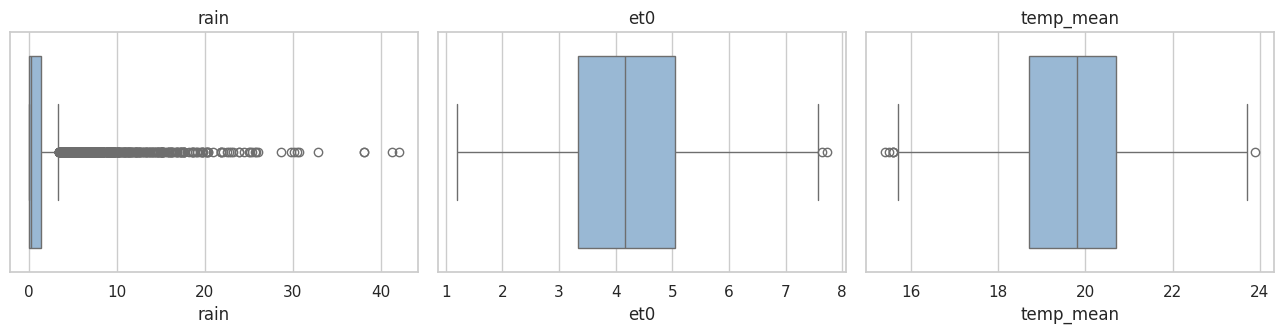

Cleaned weather: (4018, 8)
Dates: 2015-01-01 to 2025-12-31


In [ ]:
# IQR rule: a value is an 'outlier' if it is more than 1.5 x IQR beyond the middle 50%
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

outlier_counts = weather[["temp_mean", "temp_max", "humidity_mean", "rain", "et0", "wind_max"]].apply(iqr_outliers)
print(outlier_counts)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, col in zip(axes, ["rain", "et0", "temp_mean"]):
    sns.boxplot(x=weather[col], ax=ax, color="#8fb8de")
    ax.set_title(col)
plt.tight_layout(); plt.show()
print("Cleaned weather:", weather.shape)
print("Dates:", weather["date"].min().date(), "to", weather["date"].max().date())


### 1.6 Observation 1: Rainfall through the year
The chart compares monthly rainfall and water demand. We use it to identify wetter and drier periods.


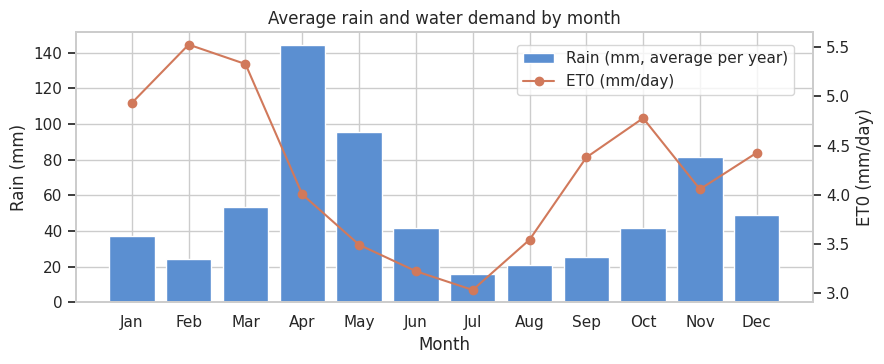

Observation 1: the wettest months are Apr, May, Nov, Mar, averaging 94 mm each, while the driest months are Feb, Aug, Jul at 20 mm each. ET0 (water demand) is highest in Feb (5.52 mm/day) and lowest in Jul (3.03 mm/day).


In [ ]:
monthly = weather.assign(month=weather["date"].dt.month).groupby("month").agg(
    rain_mm_per_year=("rain", lambda s: s.sum() / weather["date"].dt.year.nunique()),
    et0_mm_per_day=("et0", "mean"))

fig, ax1 = plt.subplots(figsize=(9, 3.8))
ax1.bar(monthly.index, monthly["rain_mm_per_year"], color="#5b8fd1", label="Rain (mm, average per year)")
ax1.set_xlabel("Month"); ax1.set_ylabel("Rain (mm)")
ax1.set_xticks(range(1, 13), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax2 = ax1.twinx()
ax2.plot(monthly.index, monthly["et0_mm_per_day"], color="#d1795b", marker="o", label="ET0 (mm/day)")
ax2.set_ylabel("ET0 (mm/day)"); ax2.grid(False)
fig.legend(loc="upper right", bbox_to_anchor=(0.9, 0.88)); plt.title("Average rain and water demand by month")
plt.tight_layout(); plt.show()

import calendar
name = lambda m: calendar.month_abbr[m]          # 3 -> 'Mar'
top = monthly["rain_mm_per_year"].sort_values(ascending=False)
print(f"Observation 1: the wettest months are {', '.join(name(m) for m in top.index[:4])}, averaging "
      f"{top.iloc[:4].mean():.0f} mm each, while the driest months are {', '.join(name(m) for m in top.index[-3:])} "
      f"at {top.iloc[-3:].mean():.0f} mm each. ET0 (water demand) is highest in {name(monthly['et0_mm_per_day'].idxmax())} "
      f"({monthly['et0_mm_per_day'].max():.2f} mm/day) and lowest in {name(monthly['et0_mm_per_day'].idxmin())} "
      f"({monthly['et0_mm_per_day'].min():.2f} mm/day).")


## 2. Devyan: Labels and exploration
### 2.1 Choose the plant groups
These five outdoor plant groups use assumed coefficients, root depths and soil capacity. The values need field validation. Rainfall applies only to plants exposed to rain.


In [ ]:
plants = pd.DataFrame([
    # group,                 example,              kc,   root_m, p,    schedule_days
    ("succulent",            "aloe, cactus",       0.20, 0.25,   0.70, 10),
    ("herb",                 "rosemary, thyme",    0.30, 0.25,   0.60, 7),
    ("flowering",            "marigold, petunia",  0.50, 0.20,   0.50, 3),
    ("fern",                 "Boston fern",        0.80, 0.20,   0.35, 3),
    ("leafy_vegetable",      "sukuma wiki (kale)", 1.00, 0.30,   0.45, 2),
], columns=["group", "example", "kc", "root_m", "p", "schedule_days"])

# Total available water in the root zone (FAO-56 eq. 82): TAW = 1000 * (field capacity - wilting point) * root depth.
# Scenario assumption: usable water fraction is 0.14. Not measured for these pots.
AVAILABLE_WATER = 0.14
plants["taw_mm"] = 1000 * AVAILABLE_WATER * plants["root_m"]
# Readily available water (FAO-56 eq. 83): the plant needs watering once it has used this much
plants["threshold_mm"] = (plants["p"] * plants["taw_mm"]).round(1)
plants


,group,example,kc,root_m,p,schedule_days,taw_mm,threshold_mm
0,succulent,"aloe, cactus",0.2,0.25,0.70,10,35.0,24.5
1,herb,"rosemary, thyme",0.3,0.25,0.60,7,35.0,21.0
2,flowering,"marigold, petunia",0.5,0.20,0.50,3,28.0,14.0
3,fern,Boston fern,0.8,0.20,0.35,3,28.0,9.8
4,leafy_vegetable,sukuma wiki (kale),1.0,0.30,0.45,2,42.0,18.9


### 2.2 Create the watering labels
Each day, plant demand increases the estimated soil deficit and rain reduces it. Reaching the threshold gives label 1, followed by an assumed full refill. These are **simulated labels**, using a simplified balance inspired by FAO-56.


In [ ]:
MIN_EFFECTIVE_RAIN = 2.0   # mm; smaller showers are ignored

w = weather[["date", "temp_mean", "temp_max", "humidity_mean", "wind_max", "rain", "et0"]].copy()
w["effective_rain"] = np.where(w["rain"] >= MIN_EFFECTIVE_RAIN, w["rain"], 0.0)

# Weather summaries
w["rain_last_3d"] = w["rain"].rolling(3, min_periods=1).sum().shift(1).fillna(0)   # rain in the 3 days BEFORE today
w["et0_last_3d"] = w["et0"].rolling(3, min_periods=1).sum().shift(1).fillna(0)     # water demand in the 3 days before today

# Days since rain of at least 2 mm
days_since_rain, counter = [], 0
for r in w["effective_rain"]:
    counter = 0 if r > 0 else counter + 1
    days_since_rain.append(counter)
w["days_since_rain"] = days_since_rain


def simulate(group_row):
    """Run our simplified reference simulation for one outdoor plant group."""
    deficit, days_since_watered = 0.0, 0
    labels, dsw, deficits = [], [], []
    for et0, rain in zip(w["et0"], w["effective_rain"]):
        days_since_watered += 1
        deficit = max(0.0, deficit + group_row.kc * et0 - rain)
        water = int(deficit >= group_row.threshold_mm)
        labels.append(water); dsw.append(days_since_watered); deficits.append(deficit)
        if water:                       # gardener waters: soil back to full, counter restarts
            deficit, days_since_watered = 0.0, 0
    out = w.copy()
    out["group"] = group_row.group
    out["kc"] = group_row.kc
    out["threshold_mm"] = group_row.threshold_mm
    out["schedule_days"] = group_row.schedule_days
    out["days_since_watered"] = dsw
    out["deficit_mm"] = deficits          # kept only for checking; NOT a model feature
    out["water_today"] = labels
    return out

data = pd.concat([simulate(row) for row in plants.itertuples()], ignore_index=True)

# Drop the first 30 days of each group: the soil starts artificially 'full' on day 1
data = data[data["date"] >= data["date"].min() + pd.Timedelta(days=30)].reset_index(drop=True)
print("Modelling dataset shape:", data.shape)
data.head()


Modelling dataset shape: (19940, 18)


,date,temp_mean,temp_max,humidity_mean,wind_max,rain,et0,effective_rain,rain_last_3d,et0_last_3d,days_since_rain,group,kc,threshold_mm,schedule_days,days_since_watered,deficit_mm,water_today
0,2015-01-31,21.3,29.9,49,20.2,0.0,6.67,0.0,0.0,17.66,11,succulent,0.2,24.5,10,1,1.334,0
1,2015-02-01,21.5,29.2,53,21.7,0.0,6.32,0.0,0.0,18.63,12,succulent,0.2,24.5,10,2,2.598,0
2,2015-02-02,21.4,28.4,58,22.7,0.0,5.88,0.0,0.0,18.95,13,succulent,0.2,24.5,10,3,3.774,0
3,2015-02-03,21.0,27.8,58,23.3,0.0,5.88,0.0,0.0,18.87,14,succulent,0.2,24.5,10,4,4.950,0
4,2015-02-04,20.7,27.3,61,22.5,0.0,5.65,0.0,0.0,18.08,15,succulent,0.2,24.5,10,5,6.080,0


### 2.3 Select the model inputs
We use weather, plant parameters and days since watering. That watering history comes from the reference simulation. Deficit is excluded to test whether the tree can approximate the rule; it can also be estimated without a sensor.


In [ ]:
FEATURES = ["temp_mean", "temp_max", "humidity_mean", "wind_max",
            "rain", "rain_last_3d", "et0", "et0_last_3d",
            "days_since_rain", "days_since_watered", "kc", "threshold_mm"]
TARGET = "water_today"

print("Missing values in features or target:", int(data[FEATURES + [TARGET]].isnull().sum().sum()))
print("Rows:", len(data), "| plant groups:", data["group"].nunique(),
      "| days per group:", len(data) // data["group"].nunique())
print("\nFeatures used by the model:")
for f in FEATURES:
    print(" -", f)


Missing values in features or target: 0
Rows: 19940 | plant groups: 5 | days per group: 3988

Features used by the model:
 - temp_mean
 - temp_max
 - humidity_mean
 - wind_max
 - rain
 - rain_last_3d
 - et0
 - et0_last_3d
 - days_since_rain
 - days_since_watered
 - kc
 - threshold_mm


### 2.4 Observation 2: How often each group needs water
Check the class balance before interpreting accuracy. These rates describe the simulation, not observed plants.


Observation 2: overall, plants need watering on 10.7% of days. By group:
   succulent          1.6% of days (about every 61.4 days)
   herb               3.5% of days (about every 28.5 days)
   flowering         10.0% of days (about every 10.0 days)
   leafy_vegetable   15.7% of days (about every 6.4 days)
   fern              22.6% of days (about every 4.4 days)


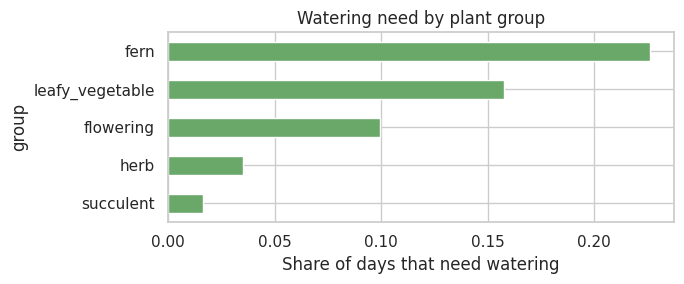

In [ ]:
overall = data[TARGET].mean()
by_group = data.groupby("group")[TARGET].mean().sort_values()
print(f"Observation 2: overall, plants need watering on {overall:.1%} of days. By group:")
for g, v in by_group.items():
    print(f"   {g:16s} {v:6.1%} of days (about every {1/v:.1f} days)" if v > 0 else f"   {g:16s} never")

by_group.plot(kind="barh", color="#6aa86a", figsize=(7, 3))
plt.xlabel("Share of days that need watering"); plt.title("Watering need by plant group")
plt.tight_layout(); plt.show()


### 2.5 Observation 3: Watering labels by month
Compare the monthly watering rate with the rainfall pattern from Ian's section.


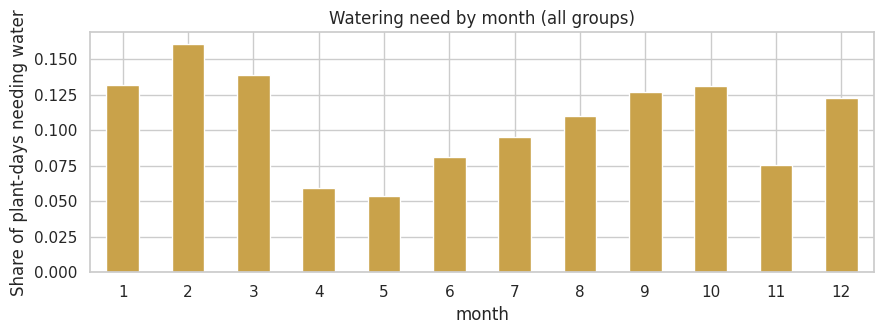

Observation 3: watering need peaks in Feb (16.1% of plant-days) and is lowest in May (5.4%). Correlation between monthly rain and monthly watering need: -0.69.


In [ ]:
seasonal = data.assign(month=data["date"].dt.month).groupby("month")[TARGET].mean()
seasonal.plot(kind="bar", color="#c9a24a", figsize=(9, 3.5), rot=0)
plt.ylabel("Share of plant-days needing water"); plt.title("Watering need by month (all groups)")
plt.tight_layout(); plt.show()

print(f"Observation 3: watering need peaks in {name(seasonal.idxmax())} ({seasonal.max():.1%} of plant-days) "
      f"and is lowest in {name(seasonal.idxmin())} ({seasonal.min():.1%}). "
      f"Correlation between monthly rain and monthly watering need: "
      f"{np.corrcoef(monthly['rain_mm_per_year'], seasonal)[0, 1]:.2f}.")


### 2.6 Observation 4: Features linked to watering
Correlation helps describe patterns. It does not prove that a feature causes watering need.


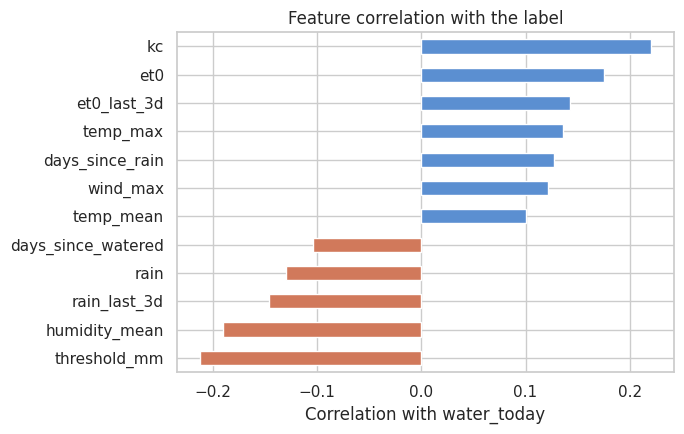

Observation 4: strongest positive links: kc (0.22), et0 (0.18), et0_last_3d (0.14)
               strongest negative links: threshold_mm (-0.21), humidity_mean (-0.19), rain_last_3d (-0.15)


In [ ]:
corr = data[FEATURES + [TARGET]].corr()[TARGET].drop(TARGET).sort_values()
corr.plot(kind="barh", color=["#d1795b" if v < 0 else "#5b8fd1" for v in corr], figsize=(7, 4.5))
plt.xlabel("Correlation with water_today"); plt.title("Feature correlation with the label")
plt.tight_layout(); plt.show()

print("Observation 4: strongest positive links:", ", ".join(f"{k} ({v:.2f})" for k, v in corr.tail(3)[::-1].items()))
print("               strongest negative links:", ", ".join(f"{k} ({v:.2f})" for k, v in corr.head(3).items()))


## 3. Alfred: Training and results
### 3.1 Split by date
Train on 2015-2022 and test on 2023-2025. All five groups on the same date stay together.


In [ ]:
train = data[data["date"].dt.year <= 2022]
test = data[data["date"].dt.year >= 2023]
X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

print(f"Train: {len(train):,} rows ({train['date'].min().date()} to {train['date'].max().date()}), "
      f"{y_train.mean():.1%} need water")
print(f"Test:  {len(test):,} rows ({test['date'].min().date()} to {test['date'].max().date()}), "
      f"{y_test.mean():.1%} need water")


Train: 14,460 rows (2015-01-31 to 2022-12-31), 10.6% need water
Test:  5,480 rows (2023-01-01 to 2025-12-31), 11.0% need water


### 3.2 Tune the Decision Tree
Five folds train on earlier years and validate on the next year, from 2018 to 2022. We choose depth, leaf size and class weighting using F1.


In [ ]:
cv = []
for validation_year in range(2018, 2023):
    fit_idx = np.flatnonzero((train["date"].dt.year < validation_year).to_numpy())
    val_idx = np.flatnonzero((train["date"].dt.year == validation_year).to_numpy())
    assert train.iloc[fit_idx]["date"].max() < train.iloc[val_idx]["date"].min()
    assert set(y_train.iloc[fit_idx]) == set(y_train.iloc[val_idx]) == {0, 1}
    cv.append((fit_idx, val_idx))
    print(validation_year, "train rows:", len(fit_idx), "validation rows:", len(val_idx))
param_grid = {"max_depth": [3, 5, 8, 12], "min_samples_leaf": [5, 20, 50],
              "class_weight": [None, "balanced"]}
tree_search = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE),
    param_grid, scoring="f1", cv=cv, n_jobs=2, return_train_score=True, error_score="raise")
tree_search.fit(X_train, y_train)
best = tree_search.best_index_
res = tree_search.cv_results_
print("Best settings:", tree_search.best_params_)
print(f"Validation F1: {res['mean_test_score'][best]:.3f} +/- {res['std_test_score'][best]:.3f}")
print(f"Training F1: {res['mean_train_score'][best]:.3f}")


2018 train rows: 5330 validation rows: 1825
2019 train rows: 7155 validation rows: 1825
2020 train rows: 8980 validation rows: 1830
2021 train rows: 10810 validation rows: 1825
2022 train rows: 12635 validation rows: 1825
Best settings: {'class_weight': None, 'max_depth': 12, 'min_samples_leaf': 5}
Validation F1: 0.757 +/- 0.021
Training F1: 0.883


### 3.3 Test on unseen years
Precision measures correct watering alerts. Recall measures reference watering requests found. F1 balances the two.


              precision    recall  f1-score   support

 not yet (0)      0.968     0.976     0.972      4878
   water (1)      0.793     0.739     0.765       602

    accuracy                          0.950      5480
   macro avg      0.881     0.858     0.869      5480
weighted avg      0.949     0.950     0.949      5480



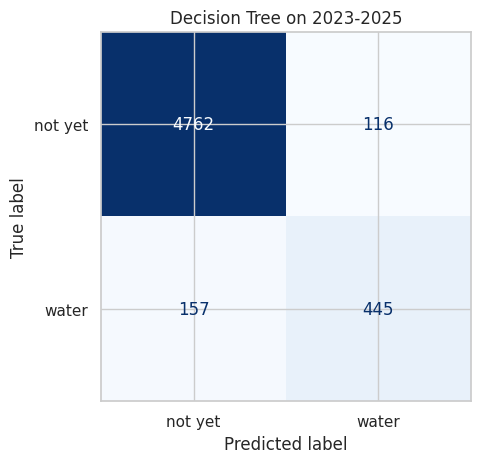

In [ ]:
tree = tree_search.best_estimator_
y_pred_tree = tree.predict(X_test)

print(classification_report(y_test, y_pred_tree, target_names=["not yet (0)", "water (1)"], digits=3))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_tree),
                       display_labels=["not yet", "water"]).plot(cmap="Blues", colorbar=False)
plt.title("Decision Tree on 2023-2025"); plt.show()


### 3.4 Read the tree
The chart shows which inputs the tree uses most. The first levels show how it makes a decision.


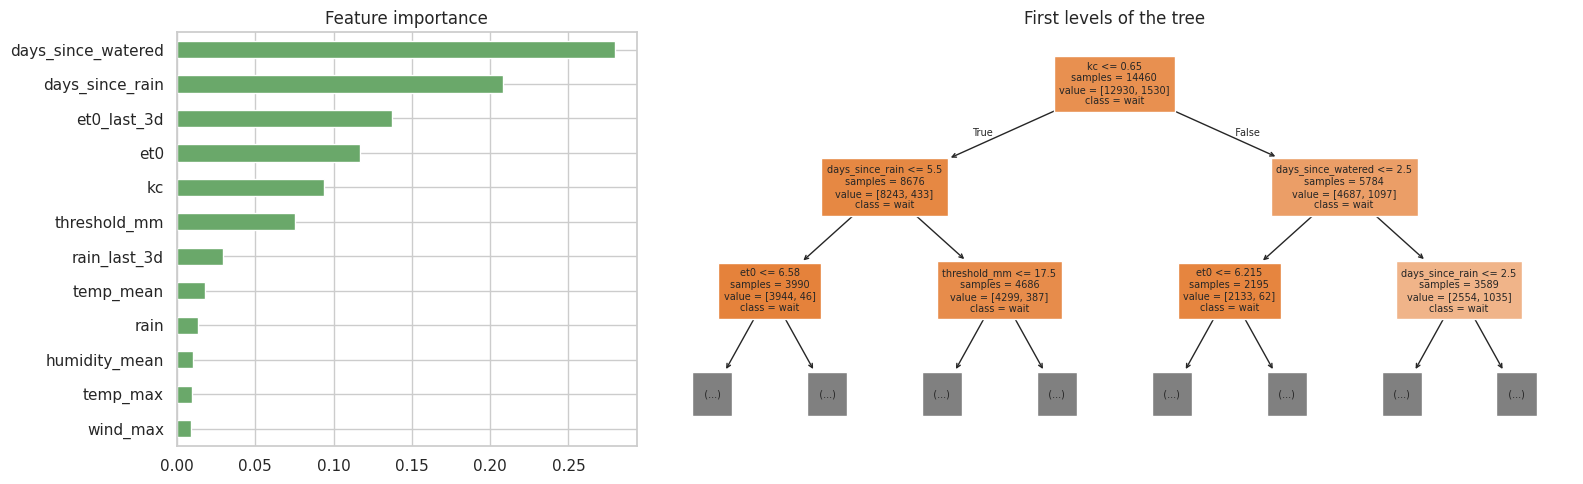

In [ ]:
importance = pd.Series(tree.feature_importances_, index=FEATURES).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [1, 2]})
importance[importance > 0].plot(kind="barh", ax=axes[0], color="#6aa86a")
axes[0].set_title("Feature importance")
plot_tree(tree, feature_names=FEATURES, class_names=["wait", "water"],
          filled=True, max_depth=2, fontsize=7, ax=axes[1], impurity=False)
axes[1].set_title("First levels of the tree")
plt.tight_layout(); plt.show()


### 3.5 Compare the models
All classifiers use the same dates, inputs and tuning folds. We also compare a chosen fixed calendar and an always-wait baseline. The direct rule generates the labels, so its perfect score is expected.


Logistic Regression best settings: {'model__C': 0.1, 'model__class_weight': 'balanced'}
K-Nearest Neighbours best settings: {'model__n_neighbors': 5, 'model__weights': 'distance'}
Random Forest best settings: {'class_weight': 'balanced', 'max_depth': 12, 'min_samples_leaf': 5}


,Accuracy,Precision,Recall,F1,CV F1 mean,CV F1 std
Decision Tree,0.950,0.793,0.739,0.765,0.757,0.021
Logistic Regression,0.725,0.257,0.797,0.389,0.363,0.023
K-Nearest Neighbours,0.876,0.325,0.123,0.178,0.165,0.029
Random Forest,0.942,0.687,0.860,0.764,0.722,0.030
Chosen fixed calendar,0.684,0.133,0.342,0.192,NaN,NaN
Always do not water,0.890,0.000,0.000,0.000,NaN,NaN
Direct reference rule,1.000,1.000,1.000,1.000,NaN,NaN


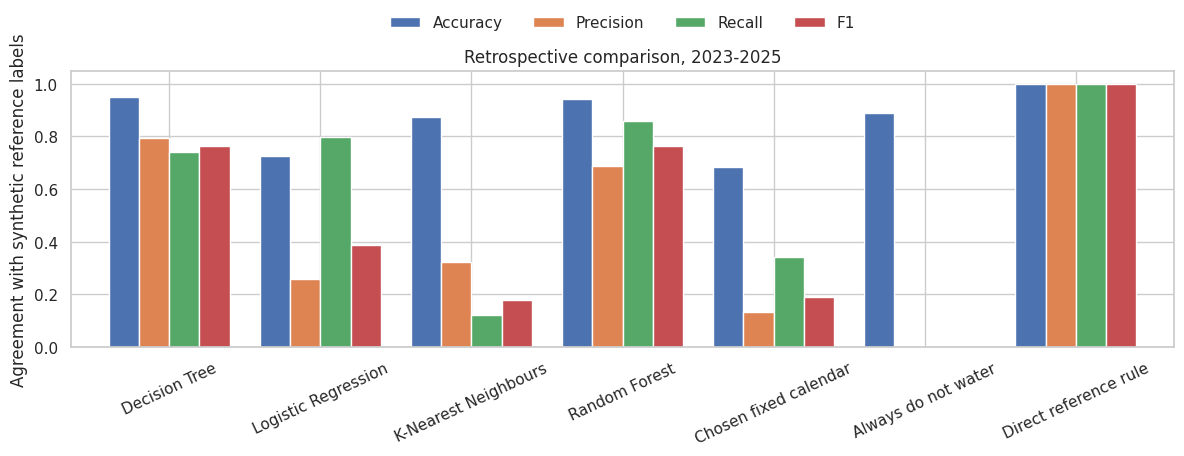

In [ ]:
candidates = {
    "Logistic Regression": (Pipeline([("scale", StandardScaler()),
        ("model", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))]),
        {"model__C": [0.1, 1, 10], "model__class_weight": [None, "balanced"]}),
    "K-Nearest Neighbours": (Pipeline([("scale", StandardScaler()), ("model", KNeighborsClassifier())]),
        {"model__n_neighbors": [5, 15, 31], "model__weights": ["uniform", "distance"]}),
    "Random Forest": (RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=1),
        {"max_depth": [6, 12], "min_samples_leaf": [5, 20], "class_weight": [None, "balanced"]})}
fitted = {"Decision Tree": tree}
cv_f1 = {"Decision Tree": (res["mean_test_score"][best], res["std_test_score"][best])}
for name, (model, grid) in candidates.items():
    search = GridSearchCV(model, grid, scoring="f1", cv=cv, n_jobs=2, error_score="raise").fit(X_train, y_train)
    fitted[name] = search.best_estimator_
    i = search.best_index_
    cv_f1[name] = (search.cv_results_["mean_test_score"][i], search.cv_results_["std_test_score"][i])
    print(name, "best settings:", search.best_params_)

def scores(y_true, y_pred):
    return {"Accuracy": accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall": recall_score(y_true, y_pred, zero_division=0),
            "F1": f1_score(y_true, y_pred, zero_division=0)}
predictions = {name: m.predict(X_test) for name, m in fitted.items()}
# Calendar carries its initial phase through the entire weather history.
day_number = (test["date"] - weather["date"].min()).dt.days + 1
predictions["Chosen fixed calendar"] = (day_number % test["schedule_days"] == 0).astype(int).to_numpy()
dummy = DummyClassifier(strategy="constant", constant=0).fit(X_train, y_train)
predictions["Always do not water"] = dummy.predict(X_test)
predictions["Direct reference rule"] = (test["deficit_mm"] >= test["threshold_mm"]).astype(int).to_numpy()
assert np.array_equal(predictions["Direct reference rule"], y_test.to_numpy())
results = pd.DataFrame({name: scores(y_test, p) for name, p in predictions.items()}).T
results["CV F1 mean"] = [cv_f1[n][0] if n in cv_f1 else np.nan for n in results.index]
results["CV F1 std"] = [cv_f1[n][1] if n in cv_f1 else np.nan for n in results.index]
display(results.round(3))
results.to_csv("model_comparison.csv")

results[["Accuracy", "Precision", "Recall", "F1"]].plot(kind="bar", figsize=(12, 5), rot=25, width=0.8)
plt.ylim(0, 1.05)
plt.ylabel("Agreement with synthetic reference labels")
plt.title("Retrospective comparison, 2023-2025")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, 1.25), ncol=4, frameon=False)
plt.tight_layout(); plt.show()


### 3.6 Findings and next steps
Scores show agreement with simulated labels under reference watering history. They do not yet show real plant health or morning forecast performance.

Next: test morning forecasts, let each method follow its own watering history, vary the soil assumptions, and check predictions against real plants.


In [ ]:
tree_f1 = results.loc["Decision Tree", "F1"]
calendar_f1 = results.loc["Chosen fixed calendar", "F1"]
print(f"Decision Tree: {results.loc['Decision Tree', 'Accuracy']:.1%} accuracy, F1 {tree_f1:.3f}")
print(f"Chosen calendar: F1 {calendar_f1:.3f}")
print(f"Random Forest: F1 {results.loc['Random Forest', 'F1']:.3f}")
print("These results measure agreement with the simulated watering rule.")
print("A short field trial is still needed before claiming practical improvement.")


Decision Tree: 95.0% accuracy, F1 0.765
Chosen calendar: F1 0.192
Random Forest: F1 0.764
These results measure agreement with the simulated watering rule.
A short field trial is still needed before claiming practical improvement.


## Appendix: Model files
The JSON contains the complete tree. Its predictions are checked against Python before export. Kotlin integration and device testing remain future work.


In [ ]:
import joblib
joblib.dump({"model": tree, "features": FEATURES, "versions": VERSIONS}, "decision_tree.joblib")
feature_units = ["C", "C", "%", "km/h", "mm", "mm", "mm", "mm", "days", "days", "ratio", "mm"]
t = tree.tree_
exported = {"schema_version": 1, "features": FEATURES, "feature_units": feature_units,
    "classes": tree.classes_.tolist(), "input_dtype": "float32",
    "scope": "Retrospective outdoor-weather prototype with synthetic labels; forecast validation pending",
    "children_left": t.children_left.tolist(), "children_right": t.children_right.tolist(),
    "feature": t.feature.tolist(), "threshold": t.threshold.tolist(),
    "predicted_class": [int(tree.classes_[np.argmax(v[0])]) for v in t.value],
    "versions": VERSIONS, "weather_sha256": provenance["sha256"],
    "plant_parameters": plants.to_dict(orient="records"), "available_water_fraction": AVAILABLE_WATER,
    "min_effective_rain_mm": MIN_EFFECTIVE_RAIN}
Path("decision_tree.json").write_text(json.dumps(exported, indent=2))
# Reload the actual serialized representation and verify its traversal.
loaded = json.loads(Path("decision_tree.json").read_text())
def predict_export(row):
    row = np.asarray(row, dtype=np.float32)
    assert len(row) == len(FEATURES) and np.isfinite(row).all()
    node = 0
    while loaded["children_left"][node] != -1:
        f = loaded["feature"][node]
        node = loaded["children_left"][node] if float(row[f]) <= loaded["threshold"][node] else loaded["children_right"][node]
    return loaded["predicted_class"][node]
export_predictions = np.array([predict_export(row) for row in X_test.to_numpy()])
assert np.array_equal(export_predictions, y_pred_tree), "JSON predictions differ from the Python model."
Path("decision_tree_rules.txt").write_text(export_text(tree, feature_names=FEATURES,
                                                        max_depth=tree.get_depth(), decimals=17))
indices = np.unique(np.linspace(0, len(X_test) - 1, 30, dtype=int))
cases = [{"features": X_test.iloc[int(i)].to_numpy().tolist(), "expected_class": int(y_pred_tree[i])} for i in indices]
Path("android_parity_cases.json").write_text(json.dumps({"feature_order": FEATURES, "cases": cases}, indent=2))
Path("run_versions.json").write_text(json.dumps({"python": platform.python_version(), "packages": VERSIONS}, indent=2))
print("JSON export matches all", len(X_test), "test predictions.")
print("Depth:", tree.get_depth(), "Leaves:", tree.get_n_leaves())
print("Saved model, full rules, JSON, Android parity cases, comparison scores and runtime versions.")


JSON export matches all 5480 test predictions.
Depth: 12 Leaves: 283
Saved model, full rules, JSON, Android parity cases, comparison scores and runtime versions.


### Save the project files
This cell creates the README and download bundle. Save the executed notebook separately using File > Download > Download .ipynb.


In [ ]:
#@title Create the download bundle
import zipfile
Path("README.md").write_text("# SemProject_MLEngine\nICS 3202 CAT 2: Smart Watering.\n\nApproach: Classification - Decision Tree (Logistic Regression / Random Forest / KNN).\n\n## Presenters\n- Ian: Sections 1.1-1.6, data and cleaning, 4 minutes.\n- Devyan: Sections 2.1-2.6, labels and exploration, 4 minutes.\n- Alfred: Sections 3.1-3.6, training and results, 4 minutes.\nThe order reflects increasing technical difficulty. Each member should understand and explain their actual contribution.\n\n## Run\nOpen DecisionTree_Base.ipynb in Colab and choose Runtime > Run all. The first run downloads ERA5 weather. Keep nairobi_era5_daily_2015_2025.csv with weather_provenance.json to repeat the same run. Save the notebook with outputs. The appendix creates SmartWatering_Artifacts.zip.\n\n## Method\nWeather covers Nairobi, 2015-2025. Labels are generated by a simplified water-balance simulation inspired by FAO-56, using assumed outdoor plant and soil parameters. Training uses 2015-2022 after a 30-day warm-up; tuning uses five expanding chronological folds validating on 2018-2022. Testing uses 2023-2025. All plant groups for each date stay together. Scaling stays inside model pipelines. Positive-class F1 is the tuning metric.\n\nThe fixed calendar is a chosen baseline, not a verified commercial app. The direct reference rule generates the labels, so its perfect score is expected. Watering history is supplied by that reference policy. Results describe single-decision agreement with synthetic labels, not autonomous app operation or plant health. Morning forecast evaluation, independent watering trajectories, parameter sensitivity and field validation remain future work.\n\n## Files\nThe bundle includes raw weather, provenance, model scores, the Python model, complete JSON tree, readable rules, Android parity cases and runtime versions. JSON traversal is checked against all test predictions. A Kotlin implementation and Android device testing are still required. Follow the exported feature order, units and float32 input convention.\n\n## Submission\nCreate the public SemProject_MLEngine repository and commit the executed notebook, README, requirements, weather CSV and provenance before 6 November 2026. The other members fork it. Verify outputs and the commit timestamp. Attend the required classes and presentation.\n\n## Sources and assistance\nOpen-Meteo historical weather API; FAO-56 (Allen et al., 1998); WUCOLS landscape context; scikit-learn documentation. Exact scenario parameters are assumptions, not measurements. Code and editing assistance: OpenAI Codex. Follow the course's actual disclosure rules.\n")
Path("requirements.txt").write_text('numpy>=1.26,<3\npandas>=2.2,<3\nmatplotlib>=3.8,<4\nseaborn>=0.13,<1\nscikit-learn>=1.5,<2\nrequests>=2.31,<3\njoblib>=1.3,<2\n')
bundle_files = ["README.md", "requirements.txt", "nairobi_era5_daily_2015_2025.csv",
                "weather_provenance.json", "model_comparison.csv", "decision_tree.joblib",
                "decision_tree.json", "decision_tree_rules.txt", "android_parity_cases.json", "run_versions.json"]
with zipfile.ZipFile("SmartWatering_Artifacts.zip", "w", zipfile.ZIP_DEFLATED) as bundle:
    for filename in bundle_files:
        bundle.write(filename)
print("Saved SmartWatering_Artifacts.zip. Download it from the Files sidebar.")


Saved SmartWatering_Artifacts.zip. Download it from the Files sidebar.


### Sources
- [Open-Meteo: historical weather](https://open-meteo.com/en/docs/historical-weather-api)
- [Allen et al. (1998): FAO-56](https://www.fao.org/4/X0490E/X0490E00.htm)
- [WUCOLS: landscape water use](https://ucanr.edu/sites/WUCOLS/)
- [Scikit-learn: time-based validation](https://scikit-learn.org/stable/modules/cross_validation.html#cross-validation-of-time-series-data)

*Code and editing assistance: OpenAI Codex.*
